# 残差连接与 Pre-Norm、Post-Norm

## 一、为什么需要残差连接？

深层网络的梯度需要逐层反向传播。假设每一层的特征变换为 $F_l$（例如 Attention 或 FFN），普通连接为：

$$x_{l+1}=F_l(x_l)$$

为了便于理解，先以标量为例，根据链式法则，经过 $n$ 层的梯度为：

$$\frac{\partial x_n}{\partial x_0}=\prod_{l=0}^{n-1}F_l'(x_l)$$

如果每层导数的绝对值都小于 1，梯度连乘后会越来越小；如果持续大于 1，则可能出现梯度爆炸。

因此，引入残差连接（Residual Connection），将输入直接加到变换结果上：

$$x_{l+1}=x_l+F_l(x_l)$$

此时，每一层的导数为：

$$\frac{\partial x_{l+1}}{\partial x_l}=1+F_l'(x_l)$$

其中的 $1$ 就是残差连接提供的恒等梯度路径（向量情况下对应单位矩阵 $I$）。当变换分支的导数接近 0 时，梯度仍可通过这条路径传播。

**残差连接主要缓解梯度消失，并不能保证避免梯度爆炸。** 同时，前向传播中网络可以在原始特征的基础上学习增量，而不必每层重新生成全部特征。


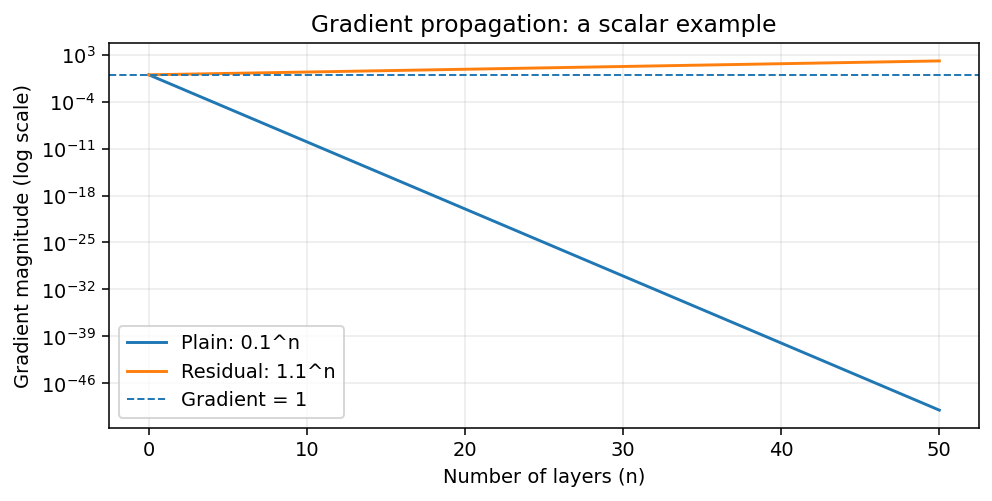

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 简化示例：假设每一层变换分支的导数始终为 0.1
layers = np.arange(0, 51)  # 网络深度
f_grad = 0.1

# 普通连接：每经过一层，梯度乘以 F'(x)
plain_grad = f_grad ** layers

# 残差连接：每经过一层，梯度乘以 1 + F'(x)
residual_grad = (1 + f_grad) ** layers

# 使用对数坐标，便于同时观察很小和很大的梯度
plt.figure(figsize=(7.2, 3.7))
plt.semilogy(layers, plain_grad, label="Plain: 0.1^n")
plt.semilogy(layers, residual_grad, label="Residual: 1.1^n")
plt.axhline(1, linestyle="--", linewidth=1, label="Gradient = 1")
plt.xlabel("Number of layers (n)")
plt.ylabel("Gradient magnitude (log scale)")
plt.title("Gradient propagation: a scalar example")
plt.grid(True, alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

图中，普通连接的梯度迅速趋近于 0；残差连接避免了这一例子中的梯度消失，但梯度仍然可能增长。这只是固定标量导数的示例，并非真实 Transformer 的梯度测量。

## 二、为什么还要考虑归一化的位置？

残差连接主要提供梯度传播路径，归一化则主要控制特征的数值尺度。当两者结合时，有两种放置归一化层的方式（$F$ 表示 Attention 或 FFN，$\operatorname{Norm}$ 表示 LayerNorm 或 RMSNorm）。

| Post-Norm（后归一化） | Pre-Norm（前归一化） |
| :--- | :--- |
| $y=\operatorname{Norm}(x+F(x))$ | $y=x+F(\operatorname{Norm}(x))$ |
| 先进行特征变换和残差相加，再归一化 | 先归一化变换分支的输入，再与原始输入相加 |
| 直接控制残差相加后的输出尺度 | 控制 Attention / FFN 的输入尺度 |

从前向传播来看，Post-Norm 更直接地控制每层相加后的输出尺度。但是，深层网络还需要考虑梯度如何反向传播。

## 三、为什么 Pre-Norm 通常更容易训练？

**Post-Norm：**

$$y=\operatorname{Norm}(x+F(x))$$

$$\frac{\partial y}{\partial x}=\operatorname{Norm}'(x+F(x))\left(1+F'(x)\right)$$

残差连接虽然提供了 $1$，但它仍然要乘以归一化层的导数。随着层数增加，梯度仍需要经过每一层归一化操作。

**Pre-Norm：**

$$y=x+F(\operatorname{Norm}(x))$$

$$\frac{\partial y}{\partial x}=1+F'(\operatorname{Norm}(x))\operatorname{Norm}'(x)$$

这里的 $1$ 不需要经过归一化或特征变换，因此保留了一条独立的恒等梯度路径。这有助于深层 Transformer 的训练稳定性。

> 上述导数采用标量形式说明链式法则。真实的 Attention、FFN 和 Norm 使用向量或张量，其导数对应雅可比矩阵，恒等路径对应 $I$，结论中的路径区别不变。

参考：[On Layer Normalization in the Transformer Architecture (ICML 2020)](https://proceedings.mlr.press/v119/xiong20b.html)。该研究从理论和实验角度比较了 Pre-LN 与 Post-LN，说明 Pre-LN 在初始化阶段具有更稳定的梯度性质。这不意味着 Pre-Norm 的最终性能一定更好。


## 四、两种结构的区别与 Transformer 中的应用

| 对比项 | Post-Norm | Pre-Norm |
| :--- | :--- | :--- |
| 归一化对象 | 残差相加后的输出 | 变换分支的输入 |
| 输出尺度控制 | 更直接 | 残差主干尺度可能累积增长 |
| 恒等梯度路径 | 仍经过归一化 | 不经过归一化 |
| 典型架构 | 原始 Transformer | LLaMA 等现代语言模型 |

Pre-Norm 也存在取舍：残差相加后的特征没有直接归一化，数值尺度可能随着层数增加而增长。因此，现代语言模型通常在全部 Transformer Block 堆叠结束后加入 Final Norm。

一个采用 Pre-Norm 的 Decoder-only Transformer Block（两个独立的归一化层）：

$$H=X+\operatorname{Attention}(\operatorname{Norm}_1(X))$$

$$Y=H+\operatorname{FFN}(\operatorname{Norm}_2(H))$$

这里 $X,H,Y$ 的形状均为 $(B,L,d_{\text{model}})$，Attention 为因果自注意力，FFN 可以采用 SwiGLU，Norm 可以采用 RMSNorm。

**总结：** 残差连接通过恒等映射提供原始特征与梯度的直接传播路径，主要缓解梯度消失；归一化通过控制特征尺度改善训练稳定性。Post-Norm 直接归一化残差相加后的输出，而 Pre-Norm 在控制变换分支输入尺度的同时，保留不经过归一化的恒等梯度路径，因此通常更适合深层 Transformer 的训练。
